# FedAvg for Time Series: Self-Supervised Learning, Anomalies, and OOD

This notebook compares centralized self-supervised training with Federated Averaging on time series data. It uses an autoencoder to reconstruct windows, then studies reconstruction error on nominal, anomalous, and out-of-distribution windows.

In [1]:
import copy, math, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix

In [2]:
SEED = 7
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_CLIENTS, WINDOW, STRIDE = 5, 96, 24
N_TRAIN_WINDOWS_PER_CLIENT = 180
N_VAL_WINDOWS, N_TEST_WINDOWS = 160, 240
BATCH_SIZE, LOCAL_EPOCHS, FED_ROUNDS = 64, 2, 12
CLIENT_FRACTION, LR = 0.8, 1e-3
print("torch", torch.__version__, "| device:", DEVICE)

torch 2.11.0+cpu | device: cpu


## Synthetic Non-IID Client Data

* Each client has a slightly different nominal frequency, phase, amplitude, and noise level.

* Anomalies and OOD regimes are reserved for evaluation.

* Training windows are unlabeled and nominal.



In [3]:
# Generates synthetic time-series sensor data
def make_stream(n, client_id=0, regime="nominal", seed=0):
    rng = np.random.default_rng(seed)
    t = np.arange(n, dtype=np.float32)
    amp, phase, freq = 0.8 + 0.12*client_id, 0.35*client_id, 1.0 + 0.035*client_id
    if regime == "ood_frequency": freq *= 1.9
    base = np.stack([
        amp*np.sin(2*np.pi*freq*t/48 + phase),
        0.65*amp*np.sin(2*np.pi*freq*t/24 + phase/2),
        0.35*amp*np.cos(2*np.pi*freq*t/72 + phase)
    ], axis=1)
    if regime == "ood_amplitude": base *= 2.5
    if regime == "ood_trend":
        base += np.stack([0.003*t, -0.002*t, 0.0015*t], axis=1)
    return (base + rng.normal(0, 0.10+0.015*client_id, base.shape)).astype(np.float32)

In [4]:
# Splits the generated time-series data into smaller windows
def make_windows(stream, window=WINDOW, stride=STRIDE):
    return np.stack([stream[i:i+window] for i in range(0, len(stream)-window+1, stride)]).astype(np.float32)

In [5]:
# Create training data for each client
client_train = [
    make_windows(make_stream((N_TRAIN_WINDOWS_PER_CLIENT-1)*STRIDE+WINDOW, cid, seed=100+cid))
    for cid in range(N_CLIENTS)
]
X_train = np.concatenate(client_train)
X_val = np.concatenate([
    make_windows(make_stream((N_VAL_WINDOWS-1)*STRIDE+WINDOW, cid, seed=300+cid))[:N_VAL_WINDOWS]
    for cid in range(N_CLIENTS)
])

In [6]:
# Print dataset dimensions
print("Per-client Train Shapes:", [x.shape for x in client_train])
print("Pooled Training Data:", X_train.shape, "| Nominal Validation:", X_val.shape)

Per-client Train Shapes: [(180, 96, 3), (180, 96, 3), (180, 96, 3), (180, 96, 3), (180, 96, 3)]
Pooled Training Data: (900, 96, 3) | Nominal Validation: (800, 96, 3)


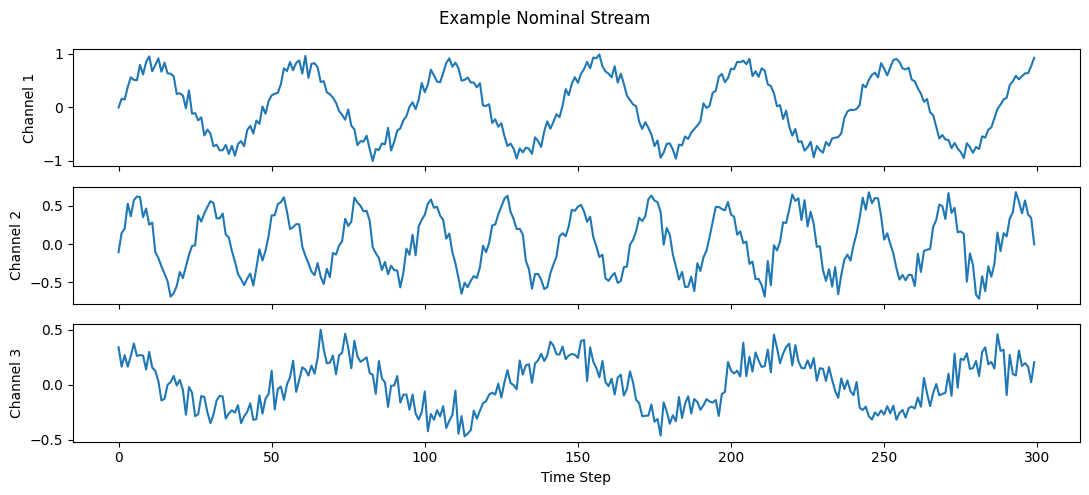

In [7]:
# Plot an example sensor stream
ex = make_stream(300, 0, seed=900)
fig, axes = plt.subplots(3, 1, figsize=(11, 5), sharex=True)
for c, ax in enumerate(axes):
    ax.plot(ex[:, c]); ax.set_ylabel(f"Channel {c+1}")
axes[-1].set_xlabel("Time Step"); fig.suptitle("Example Nominal Stream")
plt.tight_layout(); plt.show()

## Self-Supervised Objective: Reconstruct Each Window

* A small 1D convolutional autoencoder produces a per-window mean-squared reconstruction error.

* High error can indicate anomalies or benign distribution shift.

In [8]:
# A convolutional autoencoder that compresses time-series data and reconstructs it
class ConvAutoencoder(nn.Module):
    def __init__(self, channels=3, width=24):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv1d(channels, width, 5, padding=2), nn.GELU(),
            nn.Conv1d(width, width, 5, stride=2, padding=2), nn.GELU(),
            nn.Conv1d(width, width*2, 5, stride=2, padding=2), nn.GELU())
        self.decoder = nn.Sequential(
            nn.ConvTranspose1d(width*2, width, 4, stride=2, padding=1), nn.GELU(),
            nn.ConvTranspose1d(width, width, 4, stride=2, padding=1), nn.GELU(),
            nn.Conv1d(width, channels, 3, padding=1))
    def forward(self, x):
        y = self.decoder(self.encoder(x.transpose(1, 2))).transpose(1, 2)
        return y[:, :x.shape[1], :]

In [9]:
# Converts the input data for batch processing
def loader(x, shuffle=True, batch_size=BATCH_SIZE):
    return DataLoader(TensorDataset(torch.tensor(x, dtype=torch.float32)),
                      batch_size=batch_size, shuffle=shuffle)

In [10]:
# Trains the autoencoder locally
def train_local(model, x, epochs=LOCAL_EPOCHS, lr=LR):
    model.train()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        for (batch,) in loader(x, True):
            batch = batch.to(DEVICE)
            opt.zero_grad()
            loss = ((model(batch)-batch)**2).mean()
            loss.backward(); opt.step()
    return model

In [11]:
# Computes one reconstruction-error score
@torch.no_grad()
def scores(model, x):
    model.eval(); out = []
    for (batch,) in loader(x, False, 128):
        batch = batch.to(DEVICE)
        out.extend(((model(batch)-batch)**2).mean((1, 2)).cpu().numpy())
    return np.asarray(out)

In [12]:
# Aggregates local client model parameters
def fedavg(states, weights):
    total = sum(weights)
    result = copy.deepcopy(states[0])
    for key in result:
        if torch.is_floating_point(result[key]):
            result[key] = sum(sd[key] * (w/total) for sd, w in zip(states, weights))
    return result

## Train Centralized Baseline and FedAvg

In FedAvg, each selected client initializes from the global weights, performs local self-supervised updates, and returns its weights. The server averages client weights proportionally to local sample count.

In [13]:
# Trains a centralized autoencoder on the full training dataset
central = ConvAutoencoder().to(DEVICE)
central_history = []
for epoch in range(FED_ROUNDS * LOCAL_EPOCHS):
    train_local(central, X_train, epochs=1)
    central_history.append(scores(central, X_val).mean())

In [14]:
# Simulates federated learning
fed = ConvAutoencoder().to(DEVICE)
fed_history, participants = [], []
for rnd in range(FED_ROUNDS):
    selected = sorted(np.random.choice(N_CLIENTS,
        size=max(1, math.ceil(CLIENT_FRACTION*N_CLIENTS)), replace=False).tolist())
    participants.append(selected)
    states, weights = [], []
    global_state = copy.deepcopy(fed.state_dict())
    for cid in selected:
        local = ConvAutoencoder().to(DEVICE)
        local.load_state_dict(global_state)
        train_local(local, client_train[cid], LOCAL_EPOCHS)
        states.append({k: v.detach().cpu().clone() for k, v in local.state_dict().items()})
        weights.append(len(client_train[cid]))
    fed.load_state_dict(fedavg(states, weights))
    val_mse = scores(fed, X_val).mean()
    fed_history.append(val_mse)
    print(f"Round {rnd+1:02d}/{FED_ROUNDS}: val MSE={val_mse:.5f}; clients={selected}")

Round 01/12: val MSE=0.30064; clients=[0, 1, 2, 3]
Round 02/12: val MSE=0.28632; clients=[0, 1, 2, 4]
Round 03/12: val MSE=0.23270; clients=[1, 2, 3, 4]
Round 04/12: val MSE=0.16087; clients=[0, 1, 3, 4]
Round 05/12: val MSE=0.13005; clients=[1, 2, 3, 4]
Round 06/12: val MSE=0.11644; clients=[0, 1, 2, 4]
Round 07/12: val MSE=0.10760; clients=[0, 1, 2, 4]
Round 08/12: val MSE=0.10020; clients=[1, 2, 3, 4]
Round 09/12: val MSE=0.09352; clients=[0, 1, 2, 4]
Round 10/12: val MSE=0.08322; clients=[1, 2, 3, 4]
Round 11/12: val MSE=0.07522; clients=[0, 1, 2, 3]
Round 12/12: val MSE=0.06963; clients=[0, 1, 2, 4]


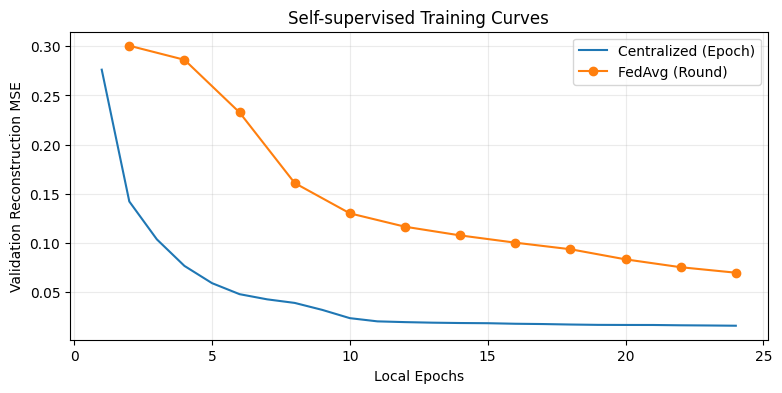

In [15]:
# Plots centralized and federated validation reconstruction errors
plt.figure(figsize=(9, 4))
plt.plot(np.arange(1, len(central_history)+1), central_history, label="Centralized (Epoch)")
plt.plot(np.arange(1, len(fed_history)+1)*LOCAL_EPOCHS, fed_history, "o-", label="FedAvg (Round)")
plt.xlabel("Local Epochs")
plt.ylabel("Validation Reconstruction MSE")
plt.title("Self-supervised Training Curves")
plt.grid(alpha=.25)
plt.legend()
plt.show()

## Evaluation Sets: Anomalies and OOD

Evaluation labels are created only here and are never used for training:
- **Point Anomaly:** spikes plus a sustained offset and fast oscillation.
- **OOD Frequency:** a different periodic operating regime.
- **OOD Amplitude:** increased signal magnitude.
- **OOD Trend:** gradual baseline drift.

OOD is reported separately, unfamiliar data is not necessarily faulty.

In [16]:
# Injects point anomalies and a temporary oscillatory anomaly
def inject_anomalies(stream, seed=0):
    rng = np.random.default_rng(seed); x = stream.copy()
    for _ in range(max(2, len(x)//250)):
        pos = int(rng.integers(10, len(x)-10)); ch = int(rng.integers(0, x.shape[1]))
        x[pos, ch] += rng.choice([-1, 1]) * rng.uniform(3, 5)
    start = int(len(x)*0.55); end = min(len(x), start + max(24, len(x)//12))
    tt = np.arange(end-start)
    x[start:end, 1] += 1.5 + 0.8*np.sin(2*np.pi*tt/5)
    return x

In [17]:
# Generates multiple time-series samples
def collect(regime, n, seed, anomaly=False):
    items = []
    for i in range(n):
        cid = i % N_CLIENTS
        stream = make_stream((WINDOW-1)*STRIDE+WINDOW, cid, regime, seed+i)
        if anomaly: stream = inject_anomalies(stream, seed+10000+i)
        items.append(make_windows(stream)[0])
    return np.asarray(items, dtype=np.float32)

In [18]:
# Generates nominal test windows representing normal time-series behavior
X_nom = collect("nominal", N_TEST_WINDOWS, 5000)

# Generates test windows with artificially injected anomalies
X_anom = collect("nominal", N_TEST_WINDOWS, 6000, anomaly=True)

# Generates out-of-distribution test windows with altered signal frequencies
X_ood_freq = collect("ood_frequency", N_TEST_WINDOWS, 7000)

# Generates out-of-distribution test windows with altered signal amplitudes
X_ood_amp = collect("ood_amplitude", N_TEST_WINDOWS, 8000)

# Generates out-of-distribution test windows with altered temporal trends
X_ood_trend = collect("ood_trend", N_TEST_WINDOWS, 9000)

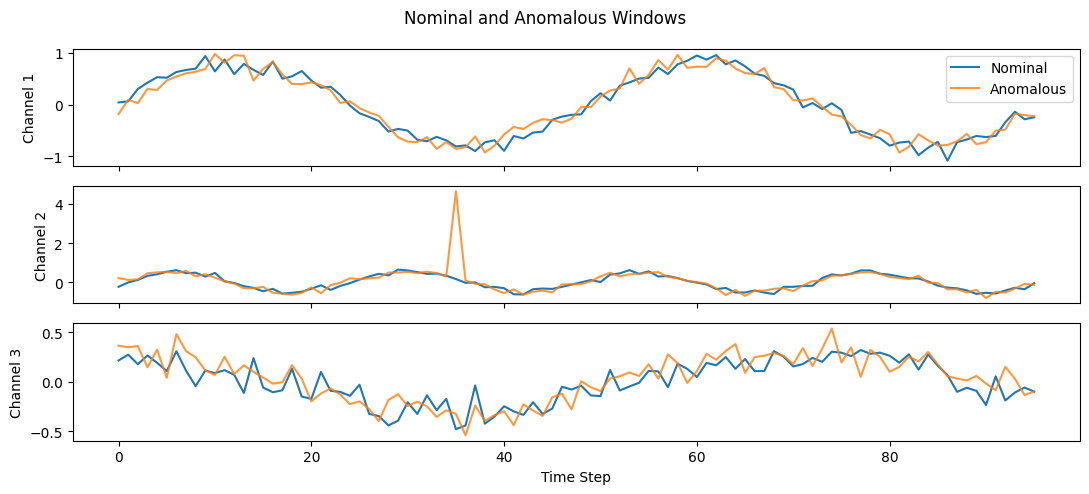

In [19]:
# Plots the first nominal and anomalous windows for each channel
fig, axes = plt.subplots(3, 1, figsize=(11, 5), sharex=True)
for c, ax in enumerate(axes):
    ax.plot(X_nom[0, :, c], label="Nominal")
    ax.plot(X_anom[0, :, c], label="Anomalous", alpha=.8)
    ax.set_ylabel(f"Channel {c+1}")
axes[0].legend()
axes[-1].set_xlabel("Time Step")
fig.suptitle("Nominal and Anomalous Windows")
plt.tight_layout()
plt.show()

## Threshold Calibration and Metrics

The threshold is the 99th percentile of nominal validation scores.

In [20]:
# Computes classification metrics
def metrics(y, s, threshold):
    pred = (s > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"AUROC": roc_auc_score(y, s),
            "AUPRC": average_precision_score(y, s),
            "Recall @ Threshold": tp/max(1, tp+fn),
            "False-Positive Rate": fp/max(1, fp+tn),
            "Precision @ Threshold": tp/max(1, tp+fp)}

In [21]:
# Defines models and groups test datasets by category
models = {"FedAvg": fed, "Centralized": central}
score_bank, rows = {}, []
categories = {"Nominal": X_nom, "Anomaly": X_anom,
              "OOD Frequency": X_ood_freq, "OOD amplitude": X_ood_amp,
              "OOD Trend": X_ood_trend}

In [22]:
# Evaluates each model
for name, model in models.items():
    threshold = float(np.quantile(scores(model, X_val), .99))
    bank = {label: scores(model, data) for label, data in categories.items()}
    bank["Threshold"] = threshold; score_bank[name] = bank
    y = np.r_[np.zeros(len(bank["Nominal"])), np.ones(len(bank["Anomaly"]))]
    s = np.r_[bank["Nominal"], bank["Anomaly"]]
    row = metrics(y, s, threshold); row["Model"] = name
    rows.append(row)
display(pd.DataFrame(rows).set_index("Model").round(4))

,AUROC,AUPRC,Recall @ Threshold,False-Positive Rate,Precision @ Threshold
Model,,,,,
FedAvg,0.6061,0.6504,0.1000,0.0000,1.0000
Centralized,0.6589,0.7354,0.3125,0.0042,0.9868


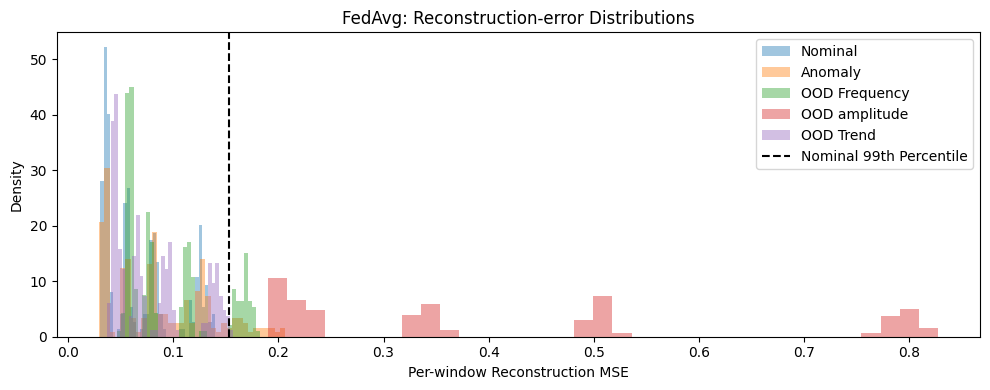

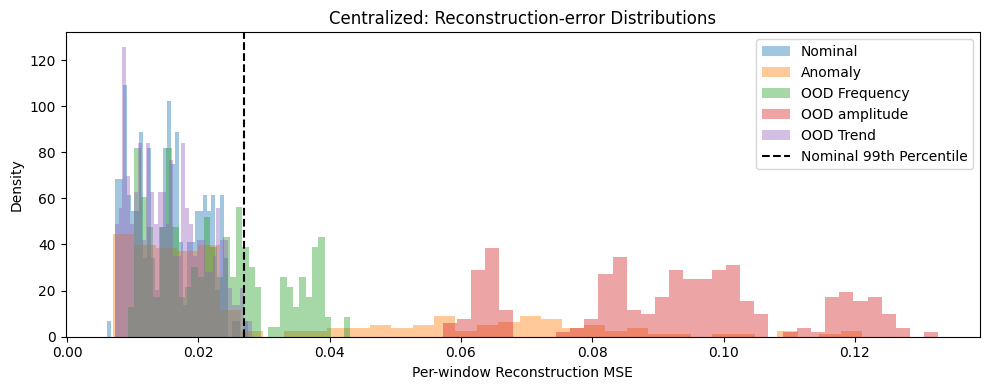

In [23]:
# Plots reconstruction-error distributions
for name, bank in score_bank.items():
    plt.figure(figsize=(10, 4))
    for label in categories:
        plt.hist(bank[label], bins=35, alpha=.42, density=True, label=label)
    plt.axvline(bank["Threshold"], color="black", linestyle="--", label="Nominal 99th Percentile")
    plt.title(f"{name}: Reconstruction-error Distributions")
    plt.xlabel("Per-window Reconstruction MSE"); plt.ylabel("Density")
    plt.legend(); plt.tight_layout(); plt.show()

## Client-Wise Diagnostic

Different clients can have different reconstruction errors simply because their normal operating regimes differ.

In [24]:
# Evaluates both models on nominal validation
rows = []
for cid in range(N_CLIENTS):
    x = make_windows(make_stream((N_VAL_WINDOWS-1)*STRIDE+WINDOW, cid, seed=12000+cid))[:N_VAL_WINDOWS]
    rows.append({"Client": cid, "FedAvg Nominal MSE": scores(fed, x).mean(),
                 "Centralized Nominal MSE": scores(central, x).mean()})
display(pd.DataFrame(rows).round(5))

,Client,FedAvg Nominal MSE,Centralized Nominal MSE
0,0,0.03559,0.00846
1,1,0.04107,0.01220
2,2,0.05262,0.01570
3,3,0.08315,0.01938
4,4,0.13682,0.02379
